# 종합실습 - 은행 고객 이탈 모델 개발 및 최적화
작성자: 신용민

## 비즈니스 목표
제한된 마케팅 예산으로 이탈 가능성이 높은 상위 10% 고객을 선별해 이탈방지 캠페인의 효율을 높인다.

- 과제 성능 기준: Validation/Test 평균 AUC
- 비즈니스 보조 기준: Top 10% Lift, Precision, Recall
- Target: Exited (1=이탈, 0=유지)


In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier
import joblib
RANDOM_STATE=42


## 1. 데이터 준비와 EDA

In [2]:
DATA_PATH=Path('bank_churn_train.csv')
if not DATA_PATH.exists():
    DATA_PATH=Path('/Users/sin-yongmin/Desktop/SKALA_4_G_SYM/2026.09.10/bank_churn_train.csv')
df=pd.read_csv(DATA_PATH)
print('shape:',df.shape)
print('target ratio:\n',df['Exited'].value_counts(normalize=True).round(4))
df.head()


shape: (2100, 14)
target ratio:
 Exited
0    0.7867
1    0.2133
Name: proportion, dtype: float64


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,baseDate,accountOpeningDate
0,15649487,Sal,578,Germany,Female,38,113150.44,2,1,0,176712.59,1,2/1/2026,4/6/2021
1,15694272,Nkemakolam,673,France,Male,30,64097.75,1,1,1,77783.35,0,2/1/2026,11/28/2024
2,15805955,L?,638,France,Female,48,138333.03,1,1,1,NaN,0,2/1/2026,12/8/2015
3,15676242,Artemova,632,Spain,Male,31,136556.44,1,1,0,82152.83,1,2/1/2026,5/2/2022
4,15756820,Fleming,655,France,Female,26,106198.50,1,0,1,32020.42,0,2/1/2026,10/30/2018


In [3]:
print(df.info())
print('\nmissing values\n',df.isna().sum()[df.isna().sum()>0])
df.select_dtypes(include=np.number).describe().T


<class 'pandas.DataFrame'>
RangeIndex: 2100 entries, 0 to 2099
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerId          2100 non-null   int64  
 1   Surname             2100 non-null   str    
 2   CreditScore         2100 non-null   int64  
 3   Geography           2058 non-null   str    
 4   Gender              2100 non-null   str    
 5   Age                 2100 non-null   int64  
 6   Balance             2100 non-null   float64
 7   NumOfProducts       2100 non-null   int64  
 8   HasCrCard           2100 non-null   int64  
 9   IsActiveMember      2100 non-null   int64  
 10  EstimatedSalary     2031 non-null   float64
 11  Exited              2100 non-null   int64  
 12  baseDate            2100 non-null   str    
 13  accountOpeningDate  2100 non-null   str    
dtypes: float64(2), int64(7), str(5)
memory usage: 229.8 KB
None

missing values
 Geography          42
EstimatedSalary 

,count,mean,std,min,25%,50%,75%,max
CustomerId,2100.0,1.568984e+07,72113.132084,15565701.00,1.562694e+07,1.568962e+07,1.575285e+07,15815560.00
CreditScore,2100.0,6.497848e+02,96.818063,350.00,5.800000e+02,6.520000e+02,7.170000e+02,850.00
Age,2100.0,3.881333e+01,10.231034,18.00,3.200000e+01,3.700000e+01,4.400000e+01,88.00
Balance,2100.0,7.660506e+04,62865.409749,0.00,0.000000e+00,9.753574e+04,1.287382e+05,250898.09
NumOfProducts,2100.0,1.536667e+00,0.591417,1.00,1.000000e+00,1.000000e+00,2.000000e+00,4.00
HasCrCard,2100.0,7.152381e-01,0.451408,0.00,0.000000e+00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,2100.0,5.142857e-01,0.499915,0.00,0.000000e+00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,2031.0,1.006112e+05,57715.705901,216.27,5.168057e+04,1.010579e+05,1.497561e+05,199857.47
Exited,2100.0,2.133333e-01,0.409759,0.00,0.000000e+00,0.000000e+00,0.000000e+00,1.00


## 2. Feature Engineering
날짜 자체보다 계좌 보유 기간과 연령 대비 연봉을 사용합니다. Target과 행 수는 변경하지 않습니다.

In [4]:
def make_features(data, use_fe=True):
    x=data.drop(columns=['Exited'], errors='ignore').copy()
    x=x.drop(columns=['CustomerId','Surname'], errors='ignore')
    if use_fe:
        base=pd.to_datetime(x.pop('baseDate'), errors='coerce')
        opening=pd.to_datetime(x.pop('accountOpeningDate'), errors='coerce')
        x['accountDuration_days']=(base-opening).dt.days
        x['salaryPerAge']=np.where(x['Age']>0, x['EstimatedSalary']/x['Age'], np.nan)
    else:
        x=x.drop(columns=['baseDate','accountOpeningDate'], errors='ignore')
    return x
X_fe=make_features(df, True)
X_base=make_features(df, False)
y=df['Exited'].astype(int)
X_train_fe,X_hold_fe,y_train,y_hold=train_test_split(X_fe,y,test_size=.4,stratify=y,random_state=RANDOM_STATE)
X_valid_fe,X_test_fe,y_valid,y_test=train_test_split(X_hold_fe,y_hold,test_size=.5,stratify=y_hold,random_state=RANDOM_STATE)
X_train_base=X_base.loc[X_train_fe.index]; X_valid_base=X_base.loc[X_valid_fe.index]; X_test_base=X_base.loc[X_test_fe.index]
print('split:',X_train_fe.shape,X_valid_fe.shape,X_test_fe.shape)


split: (1260, 11) (420, 11) (420, 11)


## 3. 공통 전처리와 비즈니스 평가 함수

In [5]:
def make_preprocessor(X):
    num=X.select_dtypes(include=np.number).columns.tolist()
    cat=[c for c in X.columns if c not in num]
    return ColumnTransformer([
        ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
        ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)
    ])

def top10_metrics(y_true, prob):
    z=pd.DataFrame({'y':np.asarray(y_true),'p':np.asarray(prob)}).sort_values('p',ascending=False)
    n=max(1,int(len(z)*.10)); top=z.iloc[:n]; overall=z.y.mean()
    return {'lift10':top.y.mean()/overall,'precision10':top.y.mean(),'recall10':top.y.sum()/z.y.sum(),'top_n':n}

def evaluate(name, pipe, Xtr,ytr,Xv,yv,Xte,yte):
    pipe.fit(Xtr,ytr)
    rows=[]
    for split,xx,yy in [('train',Xtr,ytr),('validation',Xv,yv),('test',Xte,yte)]:
        pr=pipe.predict_proba(xx)[:,1]; pred=(pr>=.5).astype(int); tm=top10_metrics(yy,pr)
        rows.append({'model':name,'split':split,'accuracy':accuracy_score(yy,pred),'f1':f1_score(yy,pred,zero_division=0),'precision':precision_score(yy,pred,zero_division=0),'recall':recall_score(yy,pred,zero_division=0),'auc':roc_auc_score(yy,pr),**tm})
    return pipe,pd.DataFrame(rows)


## 4. 기본 모델과 Feature Engineering 비교

In [6]:
rf_params={'n_estimators':300,'max_depth':10,'min_samples_leaf':3,'max_features':'sqrt','class_weight':'balanced','random_state':RANDOM_STATE,'n_jobs':-1}
base_pipe=Pipeline([('pre',make_preprocessor(X_base)),('model',RandomForestClassifier(**rf_params))])
fe_pipe=Pipeline([('pre',make_preprocessor(X_fe)),('model',RandomForestClassifier(**rf_params))])
base_pipe,base_res=evaluate('RF_baseline',base_pipe,X_train_base,y_train,X_valid_base,y_valid,X_test_base,y_test)
fe_pipe,fe_res=evaluate('RF_feature_engineering',fe_pipe,X_train_fe,y_train,X_valid_fe,y_valid,X_test_fe,y_test)
results=pd.concat([base_res,fe_res],ignore_index=True)
results.round(4)


,model,split,accuracy,f1,precision,recall,auc,lift10,precision10,recall10,top_n
0,RF_baseline,train,0.9437,0.8815,0.8000,0.9814,0.9919,4.6840,1.0000,0.4684,126
1,RF_baseline,validation,0.8571,0.6809,0.6531,0.7111,0.8603,3.3333,0.7143,0.3333,42
2,RF_baseline,test,0.8071,0.5846,0.5377,0.6404,0.8522,3.8202,0.8095,0.3820,42
3,RF_feature_engineering,train,0.9524,0.8993,0.8196,0.9963,0.9940,4.6840,1.0000,0.4684,126
4,RF_feature_engineering,validation,0.8571,0.6703,0.6630,0.6778,0.8562,3.3333,0.7143,0.3333,42
5,RF_feature_engineering,test,0.8143,0.5895,0.5545,0.6292,0.8569,3.8202,0.8095,0.3820,42


## 5. XGBoost 비교

In [7]:
xgb=Pipeline([('pre',make_preprocessor(X_fe)),('model',XGBClassifier(n_estimators=350,max_depth=4,learning_rate=.04,subsample=.85,colsample_bytree=.85,min_child_weight=3,reg_lambda=2,eval_metric='logloss',random_state=RANDOM_STATE,n_jobs=4))])
xgb_pipe,xgb_res=evaluate('XGBoost',xgb,X_train_fe,y_train,X_valid_fe,y_valid,X_test_fe,y_test)
results=pd.concat([results,xgb_res],ignore_index=True)
results.round(4)


,model,split,accuracy,f1,precision,recall,auc,lift10,precision10,recall10,top_n
0,RF_baseline,train,0.9437,0.8815,0.8000,0.9814,0.9919,4.6840,1.0000,0.4684,126
1,RF_baseline,validation,0.8571,0.6809,0.6531,0.7111,0.8603,3.3333,0.7143,0.3333,42
2,RF_baseline,test,0.8071,0.5846,0.5377,0.6404,0.8522,3.8202,0.8095,0.3820,42
3,RF_feature_engineering,train,0.9524,0.8993,0.8196,0.9963,0.9940,4.6840,1.0000,0.4684,126
4,RF_feature_engineering,validation,0.8571,0.6703,0.6630,0.6778,0.8562,3.3333,0.7143,0.3333,42
5,RF_feature_engineering,test,0.8143,0.5895,0.5545,0.6292,0.8569,3.8202,0.8095,0.3820,42
6,XGBoost,train,0.9325,0.8211,0.9466,0.7249,0.9828,4.6840,1.0000,0.4684,126
7,XGBoost,validation,0.8548,0.6013,0.7302,0.5111,0.8718,3.6667,0.7857,0.3667,42
8,XGBoost,test,0.8452,0.5517,0.7143,0.4494,0.8456,3.5955,0.7619,0.3596,42


## 6. Random Forest RandomizedSearchCV
탐색과 Cross Validation은 Train 데이터 안에서만 수행합니다.

In [8]:
search_pipe=Pipeline([('pre',make_preprocessor(X_fe)),('model',RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1,class_weight='balanced'))])
param_dist={'model__n_estimators':[200,300,500,700],'model__max_depth':[None,6,8,10,12,16],'model__min_samples_leaf':[1,2,3,5,8],'model__max_features':['sqrt','log2',.7]}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
search=RandomizedSearchCV(search_pipe,param_dist,n_iter=10,scoring='roc_auc',cv=cv,random_state=RANDOM_STATE,n_jobs=-1,refit=True,return_train_score=False)
search.fit(X_train_fe,y_train)
print('best params:',search.best_params_)
print('CV best AUC:',round(search.best_score_,4))
tuned_pipe,tuned_res=evaluate('RF_random_search',search.best_estimator_,X_train_fe,y_train,X_valid_fe,y_valid,X_test_fe,y_test)
results=pd.concat([results,tuned_res],ignore_index=True)
results.round(4)


best params: {'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 8}
CV best AUC: 0.8344


,model,split,accuracy,f1,precision,recall,auc,lift10,precision10,recall10,top_n
0,RF_baseline,train,0.9437,0.8815,0.8000,0.9814,0.9919,4.6840,1.0000,0.4684,126
1,RF_baseline,validation,0.8571,0.6809,0.6531,0.7111,0.8603,3.3333,0.7143,0.3333,42
2,RF_baseline,test,0.8071,0.5846,0.5377,0.6404,0.8522,3.8202,0.8095,0.3820,42
3,RF_feature_engineering,train,0.9524,0.8993,0.8196,0.9963,0.9940,4.6840,1.0000,0.4684,126
4,RF_feature_engineering,validation,0.8571,0.6703,0.6630,0.6778,0.8562,3.3333,0.7143,0.3333,42
5,RF_feature_engineering,test,0.8143,0.5895,0.5545,0.6292,0.8569,3.8202,0.8095,0.3820,42
6,XGBoost,train,0.9325,0.8211,0.9466,0.7249,0.9828,4.6840,1.0000,0.4684,126
7,XGBoost,validation,0.8548,0.6013,0.7302,0.5111,0.8718,3.6667,0.7857,0.3667,42
8,XGBoost,test,0.8452,0.5517,0.7143,0.4494,0.8456,3.5955,0.7619,0.3596,42
9,RF_random_search,train,0.9349,0.8647,0.7774,0.9740,0.9861,4.6840,1.0000,0.4684,126


## 7. 모델 비교와 최종 후보 선정

In [9]:
summary=results.pivot(index='model',columns='split',values=['auc','lift10','precision10','recall10']).round(4)
summary


auc                     lift10                    \
split                     test   train validation    test  train validation   
model                                                                         
RF_baseline             0.8522  0.9919     0.8603  3.8202  4.684     3.3333   
RF_feature_engineering  0.8569  0.9940     0.8562  3.8202  4.684     3.3333   
RF_random_search        0.8551  0.9861     0.8519  3.8202  4.684     3.4444   
XGBoost                 0.8456  0.9828     0.8718  3.5955  4.684     3.6667   

                       precision10                  recall10          \
split                         test train validation     test   train   
model                                                                  
RF_baseline                 0.8095   1.0     0.7143   0.3820  0.4684   
RF_feature_engineering      0.8095   1.0     0.7143   0.3820  0.4684   
RF_random_search            0.8095   1.0     0.7381   0.3820  0.4684   
XGBoost                     0.7619   1.0     0.7857   0.3596  0.4684   

                                   
split                  validation  
model                              
RF_baseline                0.3333  
RF_feature_engineering     0.3333  
RF_random_search           0.3444  
XGBoost                    0.3667

In [10]:
rank=results[results.split=='validation'].copy()
rank['avg_auc']=rank['auc']
rank=rank.merge(results[results.split=='test'][['model','auc']].rename(columns={'auc':'test_auc'}),on='model')
rank['avg_auc']=(rank['auc']+rank['test_auc'])/2
rank[['model','auc','test_auc','avg_auc','lift10','precision10','recall10']].sort_values(['lift10','avg_auc'],ascending=False).round(4)


,model,auc,test_auc,avg_auc,lift10,precision10,recall10
2,XGBoost,0.8718,0.8456,0.8587,3.6667,0.7857,0.3667
3,RF_random_search,0.8519,0.8551,0.8535,3.4444,0.7381,0.3444
1,RF_feature_engineering,0.8562,0.8569,0.8565,3.3333,0.7143,0.3333
0,RF_baseline,0.8603,0.8522,0.8563,3.3333,0.7143,0.3333


## 8. 최종 모델 저장
과제 점수용 평균 AUC와 비즈니스용 Top 10% Lift를 함께 확인한 뒤, 최종 모델을 선택합니다. 아래에서는 Validation AUC가 가장 높은 모델을 최종 후보로 사용합니다.

In [11]:
model_map={'RF_baseline':base_pipe,'RF_feature_engineering':fe_pipe,'XGBoost':xgb_pipe,'RF_random_search':tuned_pipe}
best_name=results[results.split=='validation'].sort_values(['auc','lift10'],ascending=False).iloc[0]['model']
best_model=model_map[best_name]
# 최종 운영 모델은 Train+Validation 전체로 재학습
X_trainval=X_fe.loc[list(X_train_fe.index)+list(X_valid_fe.index)]; y_trainval=y.loc[X_trainval.index]
best_model.fit(X_trainval,y_trainval)
joblib.dump(best_model,'bank_churn_final_model.pkl')
print('selected:',best_name)
print('saved: bank_churn_final_model.pkl')


selected: XGBoost
saved: bank_churn_final_model.pkl


## 9. 신규 고객 이탈 Score 생성

In [12]:
NEW_PATH=Path('bank_churn_new.csv')
if not NEW_PATH.exists(): NEW_PATH=Path('/Users/sin-yongmin/Desktop/SKALA_4_G_SYM/2026.09.10/bank_churn_new.csv')
new=pd.read_csv(NEW_PATH)
def make_new_features(data):
    x=data.copy().drop(columns=['CustomerId','Surname'],errors='ignore')
    base=pd.to_datetime(x.pop('baseDate'),errors='coerce'); opening=pd.to_datetime(x.pop('accountOpeningDate'),errors='coerce')
    x['accountDuration_days']=(base-opening).dt.days
    x['salaryPerAge']=np.where(x['Age']>0,x['EstimatedSalary']/x['Age'],np.nan)
    return x
new_x=make_new_features(new)
new_out=new[['CustomerId']].copy()
new_out['churn_score']=best_model.predict_proba(new_x)[:,1]
new_out['churn_pred']=(new_out['churn_score']>=.5).astype(int)
new_out.sort_values('churn_score',ascending=False).to_csv('bank_churn_final_predictions.csv',index=False)
new_out.head(10)


,CustomerId,churn_score,churn_pred
0,15758836,0.019464,0
1,15610446,0.991199,1
2,15695632,0.098708,0
3,15719309,0.115358,0
4,15599268,0.019755,0
5,15805112,0.182619,0
6,15769312,0.132440,0
7,15706021,0.055419,0
8,15570417,0.031132,0
9,15743532,0.182961,0


## 10. 결과 그래프

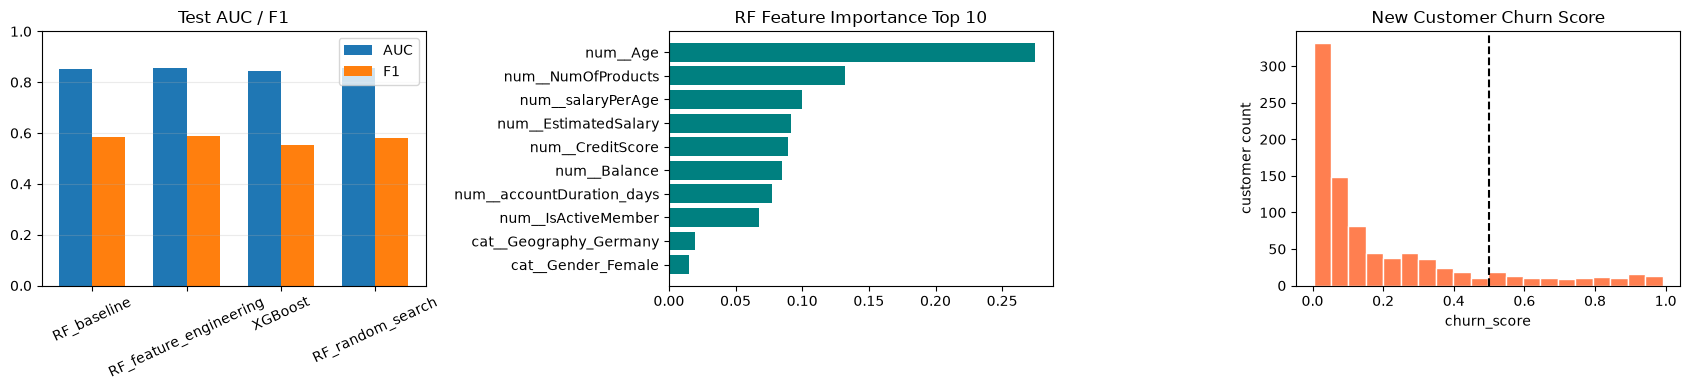

In [13]:
fig,axs=plt.subplots(1,3,figsize=(17,4))
t=results[results.split=='test']; x=np.arange(len(t)); w=.35
axs[0].bar(x-w/2,t.auc,w,label='AUC'); axs[0].bar(x+w/2,t.f1,w,label='F1'); axs[0].set_xticks(x,t.model,rotation=25); axs[0].set_ylim(0,1); axs[0].set_title('Test AUC / F1'); axs[0].legend(); axs[0].grid(axis='y',alpha=.25)
rf_imp=pd.DataFrame({'feature':fe_pipe.named_steps['pre'].get_feature_names_out(),'importance':fe_pipe.named_steps['model'].feature_importances_}).sort_values('importance').tail(10)
axs[1].barh(rf_imp.feature,rf_imp.importance,color='teal'); axs[1].set_title('RF Feature Importance Top 10')
axs[2].hist(new_out.churn_score,bins=20,color='coral',edgecolor='white'); axs[2].axvline(.5,color='black',ls='--'); axs[2].set_title('New Customer Churn Score'); axs[2].set_xlabel('churn_score'); axs[2].set_ylabel('customer count')
plt.tight_layout(); plt.show()
results.to_csv('bank_churn_experiment_results.csv',index=False)


## 결론 작성 틀
- 비즈니스 목적: 상위 10% 이탈 위험 고객을 선별해 캠페인 효율을 높임
- 최종 모델: Validation AUC와 Top 10% Lift를 함께 비교해 선정
- 평균 AUC: Validation/Test AUC의 평균으로 기록
- 한계: 캠페인 비용과 고객 유지 수익 정보가 없으므로 실제 수익 기준 최적화는 수행하지 않음
